# Figure: dipole model against the exact radiation integral

Generates `radiated_fields_models.svg` for the page *Theory → Radiated fields, directivity and gain*.

Antenna: the centre-fed strip of Ding et al. (2013) used on the *Excitations* page (75 MHz, 2 m × 5 cm, gap 50 mm, structured mesh, 24 to 324 triangles). For each mesh the current is solved with the solver, then the radiated power is computed four ways:

1. $\tfrac12 I^\mathsf{H} R\, I$ with $R = \mathrm{Re}\,Z$ (the impedance matrix itself), the reference;
2. the exact radiation integral of the RWG currents, `solver.optim.farfield.RadiationOperator` (Gauss rule on every triangle, Gauss–Legendre sphere);
3. the **dipole model** used by `solver/efield/` (`dipole_parameters.compute_dipole_center_moment`), integrated with `efield2.compute_total_radiated_power` over the same sphere mesh as `efield2` (radius 100 m, one point per facet);
4. the same dipole model integrated on the Gauss–Legendre sphere of item 2, to separate the error of the model from the error of the sphere integration.

The input power of the port ($P_\mathrm{in}$ from `rwg4.compute_port_results`) is printed too.

The sphere mesh is created by the solver's `gmsh_function.create_hollow_sphere` in a temporary folder; nothing is written to `data/`.

In [1]:
%matplotlib inline
import datetime
import json
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from fontTools.ttLib import TTFont
from matplotlib import font_manager

from solver.optim.geometries.planar import tensor_grid_mesh
from solver.optim.farfield import RadiationOperator
from solver.rwg.rwg3 import calculate_z_matrice
from solver.rwg.rwg4 import compute_port_results
from solver.utils.gap_source import multiple_gap_sources
from solver.utils.dipole_parameters import compute_dipole_center_moment, compute_e_h_field
from solver.utils.gmsh_function import create_hollow_sphere, extract_msh_to_mat
from solver.efield.efield2 import load_or_create_hollow_sphere, compute_total_radiated_power

OUT_DIR = Path("../source/figures/generated")
OUT_DIR.mkdir(parents=True, exist_ok=True)

BLUE, AMBER, INK, GREY = "#2563a6", "#e28a36", "#142b45", "#9aa5b1"
font_cache = Path(tempfile.gettempdir()) / "antenna_solver_docs_fonts"
font_cache.mkdir(exist_ok=True)
for variant in ("400-normal", "400-italic", "700-normal"):
    ttf = font_cache / f"iosevka-{variant}.ttf"
    if not ttf.exists():
        font = TTFont(Path("../source/_static/fonts/iosevka") / f"iosevka-latin-{variant}.woff2")
        font.flavor = None
        font.save(ttf)
    font_manager.fontManager.addfont(str(ttf))
plt.rcParams.update({
    "font.family": "Iosevka", "font.size": 11, "svg.fonttype": "path",
    "mathtext.fontset": "custom", "mathtext.rm": "Iosevka",
    "mathtext.it": "Iosevka:italic", "mathtext.bf": "Iosevka:bold",
})

LENGTH, WIDTH, GAP, FREQ, V0 = 2.0, 0.05, 0.05, 75e6, 1.0
TRIANGLES = [24, 44, 84, 164, 324]

# The sphere of efield2 (unit sphere from create_hollow_sphere, scaled by 100 -> radius 100 m),
# built in a temporary folder.
tmp = Path(tempfile.mkdtemp(prefix="mom_docs_sphere_"))
create_hollow_sphere(save_msh_file=str(tmp / "hollow_sphere.msh"))
extract_msh_to_mat(str(tmp / "hollow_sphere.msh"), str(tmp / "hollow_sphere.mat"))
sphere_points, sphere_triangles = load_or_create_hollow_sphere(str(tmp / "hollow_sphere.msh"), str(tmp / "hollow_sphere.mat"))
print("sphere radius:", round(float(np.linalg.norm(sphere_points[:, 0])), 3), "m")

Hollow sphere loaded: 5150 points, 10296 triangles.
sphere radius: 100.0 m


In [2]:
def strip_with_gap(W, patches):
    n_out = (patches // 2 - 2) // 2
    left = np.linspace(-LENGTH / 2, -W / 2, n_out + 1)
    return tensor_grid_mesh(np.concatenate([left, [0.0], -left[::-1]]), np.array([-WIDTH / 2, WIDTH / 2]))

def dipole_power_gauss_sphere(op, eta, k_c, moment, centre, radius=100.0):
    """The same dipole-model field, integrated on a Gauss-Legendre x trapezoid sphere grid
    (the grid of RadiationOperator.default_sphere_grid) instead of the faceted sphere of efield2."""
    n_t, n_p = op.default_sphere_grid()
    u_nodes, w_u = np.polynomial.legendre.leggauss(n_t)
    phis = 2 * np.pi * np.arange(n_p) / n_p
    total = 0.0
    for ui, wi in zip(u_nodes, w_u):
        st = np.sqrt(1 - ui * ui)
        for ph in phis:
            obs = radius * np.array([st * np.cos(ph), st * np.sin(ph), ui])
            *_, u, _ = compute_e_h_field(obs, eta, k_c, moment, centre)
            total += wi * (2 * np.pi / n_p) * u
    return total

rows = []
for patches in TRIANGLES:
    mesh = strip_with_gap(GAP, patches)
    tri, edg = mesh.triangles, mesh.edges
    V, feeding = multiple_gap_sources(tri, edg, mesh.vecteurs_rho, V0, [[0, 0, 0]], "x", GAP)
    omega, mu, eps, c, eta, Z = calculate_z_matrice(mesh.points, tri, edg, FREQ)
    I = np.linalg.solve(Z, V)
    p_in = compute_port_results(V, I, feeding, V0, [[0, 0, 0]], verbose=False)[0]["power"]
    p_R = 0.5 * np.real(np.conj(I) @ Z.real @ I)
    op = RadiationOperator(mesh.points, tri, edg, FREQ)
    p_exact = op.radiated_power_sphere(I)
    k_c = 1j * omega / c
    centre, moment = compute_dipole_center_moment(tri, edg, I)
    p_dip, u_tri = compute_total_radiated_power(sphere_points, sphere_triangles, eta, k_c, moment, centre)
    p_dip_gauss = dipole_power_gauss_sphere(op, eta, k_c, moment, centre)
    rows.append(dict(patches=patches, N=int(edg.total_number_of_edges), p_in=float(p_in), p_R=float(p_R),
                     p_exact=float(p_exact), p_dip=float(p_dip), p_dip_gauss=float(p_dip_gauss),
                     d_dip_efield2=float(4 * np.pi * u_tri.max() / p_dip),
                     mesh=mesh, I=I, op=op, eta=eta, k_c=k_c, moment=moment, centre=centre))

print(f"{'tri':>4s} {'N':>4s} {'P_in (W)':>11s} {'(P_in-P_R)/P_R':>15s} {'(P_exact-P_R)/P_R':>18s} "
      f"{'dipole, efield2 sphere':>23s} {'dipole, Gauss sphere':>21s} {'eta efield2':>12s} {'D efield2':>10s}")
for r in rows:
    rel_ = lambda key: (r[key] - r['p_R']) / r['p_R']
    print(f"{r['patches']:4d} {r['N']:4d} {r['p_in']:11.4e} {rel_('p_in'):15.2e} {rel_('p_exact'):18.2e} "
          f"{rel_('p_dip'):23.2e} {rel_('p_dip_gauss'):21.2e} {min(r['p_dip'] / r['p_in'], 1.0):12.4f} {r['d_dip_efield2']:10.4f}")

[calculate_z_matrice] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (163x163 edges).


[calculate_z_matrice] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (323x323 edges).


 tri    N    P_in (W)  (P_in-P_R)/P_R  (P_exact-P_R)/P_R  dipole, efield2 sphere  dipole, Gauss sphere  eta efield2  D efield2
  24   23  4.4839e-03       -7.74e-16          -2.28e-14                1.91e-03              1.54e-03       1.0000     1.6512
  44   43  4.4055e-03       -1.38e-15          -1.75e-14                9.14e-04              5.51e-04       1.0000     1.6542
  84   83  4.3638e-03        1.99e-16           1.79e-14                6.61e-04              2.98e-04       1.0000     1.6554
 164  163  4.3399e-03        2.00e-16          -1.02e-14                5.97e-04              2.34e-04       1.0000     1.6560
 324  323  4.3241e-03        1.00e-15           2.02e-13                5.80e-04              2.17e-04       1.0000     1.6562


In [3]:
# Is the Gauss-sphere value of the dipole model converged? Finest mesh: twice the grid, then a sphere 10 times larger.
def dipole_power_gauss_grid(n_t, n_p, eta, k_c, moment, centre, radius):
    u_nodes, w_u = np.polynomial.legendre.leggauss(n_t)
    phis = 2 * np.pi * np.arange(n_p) / n_p
    total = 0.0
    for ui, wi in zip(u_nodes, w_u):
        st = np.sqrt(1 - ui * ui)
        for ph in phis:
            obs = radius * np.array([st * np.cos(ph), st * np.sin(ph), ui])
            *_, u, _ = compute_e_h_field(obs, eta, k_c, moment, centre)
            total += wi * (2 * np.pi / n_p) * u
    return total

f = rows[-1]
n_t, n_p = f["op"].default_sphere_grid()
checks = {
    f"grid {n_t}x{n_p}, r = 100 m": f["p_dip_gauss"],
    f"grid {2 * n_t}x{2 * n_p}, r = 100 m": dipole_power_gauss_grid(2 * n_t, 2 * n_p, f["eta"], f["k_c"], f["moment"], f["centre"], 100.0),
    f"grid {2 * n_t}x{2 * n_p}, r = 1000 m": dipole_power_gauss_grid(2 * n_t, 2 * n_p, f["eta"], f["k_c"], f["moment"], f["centre"], 1000.0),
}
gauss_checks = {label: float((p - f["p_R"]) / f["p_R"]) for label, p in checks.items()}
for label, value in gauss_checks.items():
    print(f"{f['patches']} triangles, dipole model, {label}: (P - P_R)/P_R = {value:.3e}")

324 triangles, dipole model, grid 15x30, r = 100 m: (P - P_R)/P_R = 2.174e-04
324 triangles, dipole model, grid 30x60, r = 100 m: (P - P_R)/P_R = 2.174e-04
324 triangles, dipole model, grid 30x60, r = 1000 m: (P - P_R)/P_R = 2.174e-04


max D exact = 1.6573 (2.19 dBi), max D dipole (efield2 normalisation) = 1.6560; max |difference| within 20 dB of the peak: 0.004 dB


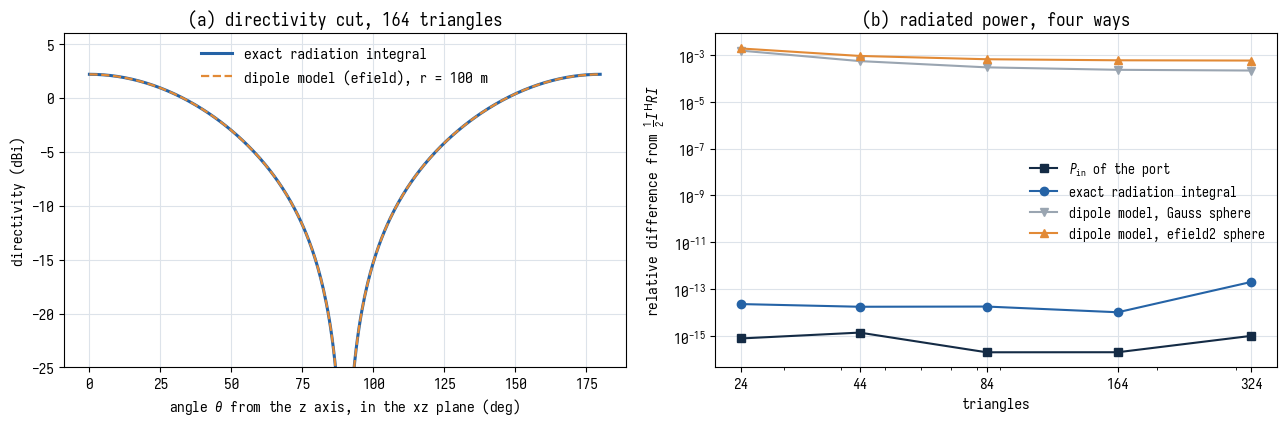

In [4]:
# Directivity in the plane of the strip axis (xz plane), 164 triangles: dipole model vs exact
r = rows[-2]
theta = np.linspace(1e-3, np.pi - 1e-3, 361)
u_t, u_p = r["op"].intensity(r["I"], theta, np.zeros_like(theta))
D_exact = 4 * np.pi * (u_t + u_p) / r["p_exact"]
R_OBS = 100.0                                    # same radius as efield2 / efield3
D_dip = np.empty_like(theta)
for i, th in enumerate(theta):
    obs = R_OBS * np.array([np.sin(th), 0.0, np.cos(th)])
    *_, u, _ = compute_e_h_field(obs, r["eta"], r["k_c"], r["moment"], r["centre"])
    D_dip[i] = 4 * np.pi * u / r["p_dip"]
dB_exact, dB_dip = 10 * np.log10(D_exact), 10 * np.log10(D_dip)
within_20 = dB_exact > dB_exact.max() - 20
print(f"max D exact = {D_exact.max():.4f} ({dB_exact.max():.2f} dBi), max D dipole (efield2 normalisation) = {D_dip.max():.4f}; "
      f"max |difference| within 20 dB of the peak: {np.max(np.abs(dB_dip - dB_exact)[within_20]):.3f} dB")

fig, (ax_d, ax_p) = plt.subplots(1, 2, figsize=(13, 4.4))
deg = np.degrees(theta)
ax_d.plot(deg, dB_exact, color=BLUE, lw=2.2, label="exact radiation integral")
ax_d.plot(deg, dB_dip, color=AMBER, lw=1.6, ls="--", label="dipole model (efield), r = 100 m")
ax_d.set_ylim(-25, 6)
ax_d.set_xlabel(r"angle $\theta$ from the z axis, in the xz plane (deg)")
ax_d.set_ylabel("directivity (dBi)")
ax_d.set_title(f"(a) directivity cut, {r['patches']} triangles")
ax_d.legend(frameon=False, loc="upper center")

tri_n = [x["patches"] for x in rows]
rel = lambda key: [abs(x[key] - x["p_R"]) / x["p_R"] for x in rows]
ax_p.loglog(tri_n, np.maximum(rel("p_in"), 1e-16), "-s", color=INK, label=r"$P_\mathrm{in}$ of the port")
ax_p.loglog(tri_n, np.maximum(rel("p_exact"), 1e-16), "-o", color=BLUE, label="exact radiation integral")
ax_p.loglog(tri_n, np.maximum(rel("p_dip_gauss"), 1e-16), "-v", color=GREY, label="dipole model, Gauss sphere")
ax_p.loglog(tri_n, np.maximum(rel("p_dip"), 1e-16), "-^", color=AMBER, label="dipole model, efield2 sphere")
ax_p.set_xticks(tri_n)
ax_p.set_xticklabels([str(t) for t in tri_n])
ax_p.set_xlabel("triangles")
ax_p.set_ylabel(r"relative difference from $\frac{1}{2}I^\mathsf{H} R I$")
ax_p.set_title("(b) radiated power, four ways")
ax_p.legend(frameon=False, fontsize=10, loc="center right")
for ax in (ax_d, ax_p):
    ax.grid(True, which="major", color="#dde3ea", lw=0.8)
fig.tight_layout()
fig.savefig(OUT_DIR / "radiated_fields_models.svg", bbox_inches="tight", facecolor="white")
plt.show()

In [5]:
def git_commit(repo=Path("../..")):
    """Current commit, read from .git directly (git may not be on the kernel's PATH)."""
    git_dir = repo / ".git"
    head = (git_dir / "HEAD").read_text().strip()
    if not head.startswith("ref: "):
        return head[:7]
    ref_file = git_dir / head[5:]
    if ref_file.exists():
        return ref_file.read_text().strip()[:7]
    for line in (git_dir / "packed-refs").read_text().splitlines():
        if line.endswith(" " + head[5:]):
            return line.split()[0][:7]
    return "unknown"

provenance = {
    "figure": "radiated_fields_models.svg",
    "notebook": "documentation/figure_notebooks/theory_radiated_fields.ipynb",
    "solver_commit": git_commit(),
    "generated": datetime.date.today().isoformat(),
    "case": {"length_m": LENGTH, "width_m": WIDTH, "gap_m": GAP, "frequency_hz": FREQ},
    "sphere": {"radius_m": round(float(np.linalg.norm(sphere_points[:, 0])), 3), "triangles": int(sphere_triangles.shape[1])},
    "rows": [{k: v for k, v in x.items() if k in ("patches", "N", "p_in", "p_R", "p_exact", "p_dip", "p_dip_gauss", "d_dip_efield2")} for x in rows],
    "dipole_gauss_convergence_324": gauss_checks,
    "cut_164": {"max_D_exact": float(D_exact.max()), "max_D_dipole": float(D_dip.max()),
                "max_abs_diff_dB_within_20dB": float(np.max(np.abs(dB_dip - dB_exact)[within_20]))},
}
(OUT_DIR / "radiated_fields.json").write_text(json.dumps(provenance, indent=2), encoding="utf-8")
print(json.dumps({k: provenance[k] for k in ("dipole_gauss_convergence_324", "cut_164")}, indent=2))

{
  "dipole_gauss_convergence_324": {
    "grid 15x30, r = 100 m": 0.00021743637376140184,
    "grid 30x60, r = 100 m": 0.00021743460493594497,
    "grid 30x60, r = 1000 m": 0.00021743041409543593
  },
  "cut_164": {
    "max_D_exact": 1.6572942472142564,
    "max_D_dipole": 1.655959106825469,
    "max_abs_diff_dB_within_20dB": 0.003500149688797194
  }
}
